In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import brute
%config InlineBackend.figure_format = "retina"

In [2]:
import warnings
warnings.filterwarnings(action = "ignore")

In [3]:
class StochasticOscillator():
    '''
    Attributes:
    ===========
    symbol: the instrument ticker for the trading strategy on it.
    data : pd.DataFrame
        It is dataframe within the four columns: Open , High , Low , Close.
    periods: int
        It is the period used to calculate two features: 
        roll_low & roll_up, which are keys to compute (K): Fast-Stochastic Calculator & (D) : Slow-Stochastic Calculator.
    start: str
        starting date of our trading; format: "YYYY-MM-DD".
    end: str
        ending date of the trading strategy; format: "YYYY-MM-DD".
    tc: float
        proportional trading cost

    Methods:
    ========
    get_data():
    '''
    def __init__(self , symbol:str , data: pd.DataFrame , periods: int, moving_avg : int ,  start : str , end : str , tc : float):
        self.symbol = symbol
        self.data = data
        self.periods = periods
        self.moving_avg = moving_avg
        self.start = start
        self.end = end
        self.tc = tc
        self.get_data()
        self.results = None
        self.KPI = None
        self.KPI_table = None

    def __repr__(self):
        rep = f"StochasticOscillator(symbol = {self.symbol} | start : {self.start} | end : {self.end} | periods : {self.periods} | moving_average: {self.moving_avg} | trading cost : {self.tc})"
        return rep


    def get_data(self , start = None , end = None):
        if start is not None or end is not None:
            self.start = start 
            self.end = end
        else:
            pass
        raw = self.data.loc[self.start : self.end]
        raw["roll_low"] = raw["Low"].rolling(window=self.periods).min()
        raw["roll_high"] = raw["High"].rolling(window=self.periods).max()
        raw["K"] = (raw["Close"] - raw["roll_low"]) / (raw["roll_high"] - raw["roll_low"]) * 100 # Fast Stochatic Indicator
        raw["D"] = raw["K"].rolling(window = self.moving_avg).mean() # Slow Stochastic Indicator
        raw = raw.dropna()
        self.data = raw
        return raw

    def trading_strategy(self , displaying_mode = None):
        '''trading strategy implemented by the stochastic oscillator strategy 
           comparasion with the buy&hold strategy.
        
        Parameters:
        ===========
        displaying_mode : str , optional
            'tabular' : returns styled KPI table.
            'value' : return the single value: the performance of our trading strategy.
        '''
        data = self.data.copy()
        data["position"] = np.where(data["K"] > data["D"] , +1 , -1)
        data["trades"] = data["position"].diff().fillna(value = 0).abs()
        data["log_ret"] = np.log(data["Close"]/data["Close"].shift(+1))
        data["strategy_ret"] = data["position"].shift(1) * data["log_ret"]
        data["strategy_ret_net"] = data["strategy_ret"] - data["trades"] * self.tc
        data["cum_log_ret"] = np.exp(data["log_ret"].cumsum())
        data["cum_strategy_ret"] = np.exp(data["strategy_ret"].cumsum())
        data["cum_strategy_ret_net"] = np.exp(data["strategy_ret_net"].cumsum())
        data = data.dropna()
        self.results = data

        # Extract final performance values:
        strategy_performance = data["cum_strategy_ret_net"].iloc[-1]
        buy_and_hold_performance = data["cum_log_ret"].iloc[-1]
        out_performance = strategy_performance - buy_and_hold_performance

        self.KPI = pd.DataFrame(
            {"Strategy" : strategy_performance ,
            "Buy & Hold" : buy_and_hold_performance ,
            "Out Performance" : out_performance,
            "Ann. Return Buy & Hold" : data["log_ret"].mean() * 252,
            "Ann. Return Strategy" : data["strategy_ret_net"].mean() * 252,
            "Ann. Risk Buy & Hold" : np.sqrt(data["log_ret"].var() * 252),
            "Ann. Risk Strategy" : np.sqrt(data["strategy_ret_net"].var() * 252),
            } , 
            index = [f"Stochastic Oscillator: symbol : {self.symbol} | periods : {self.periods} | moving_avg : {self.moving_avg}"]
        )

        self.KPI.index.name = "Performance"
        self.KPI_table = self.KPI.T.style.format("{:.2%}")

        if displaying_mode == "tabular":
            return self.KPI_table
        
        elif displaying_mode == "value":
            return float(strategy_performance)        
        else:
            print("Display mode not specified.")
            return None

    def set_parameters(self , new_periods = None , new_moving_avg = None):
         if self.data is None or self.data.empty:
            raise AttributeError("Data not loaded. Call get_data() first.")
         new_raw = self.data.loc[self.start : self.end]
         if new_periods is not None:
             self.periods = int(new_periods)
         if new_moving_avg is not None:
             self.moving_avg = int(new_moving_avg)

         new_raw["roll_low"] = new_raw["Low"].rolling(window=new_periods).min()
         new_raw["roll_high"] = new_raw["High"].rolling(window=new_periods).max()
         new_raw["K"] = (new_raw["Close"] - new_raw["roll_low"]) / (new_raw["roll_high"] - new_raw["roll_low"]) * 100 # Fast Stochatic Indicator
         new_raw["D"] = new_raw["K"].rolling(window = self.moving_avg).mean() # Slow Stochastic Indicator
         new_raw = new_raw.dropna()
         new_raw = new_raw.dropna()
         self.data = new_raw

    def optimized_trading_strategy(self , periods_range:tuple , moving_avg_range : tuple):
        '''----'''
        def objective_function(x):
            self.set_parameters(x[0] , x[1])
            val = self.trading_strategy(displaying_mode='value')
            return -1*val
        print("starting optimization ... This may take time depending on the range size.")
        res = brute(func = objective_function , ranges = (periods_range , moving_avg_range))
        best_periods = res[0]
        best_moving_avg = res[1]
        print(f"Optimal Parameters found : periods {best_periods} | best Moving_avg : {best_moving_avg}")
        return self.trading_strategy(displaying_mode='tabular')



    def plot_results(self):
        '''to plot the result of the stochastic oscillator trading strategy'''
        data = self.results
        fig , ax = plt.subplots(figsize = (14,6))
        ax.plot(data['cum_log_ret'] , color = "steelblue" , lw = 3 , label = 'Buy & Hold Strategy')
        ax.plot(data['cum_strategy_ret'] , color = "green" , lw = 3 , label = 'Stochastic Oscillator Strategy')
        ax.plot(data['cum_strategy_ret_net'] , color = "orange" , lw = 3 , label = 'Net Stochastic Oscillator Strategy')
        ax.set_title(f"{self.symbol}: Stochastic Oscillator VS Buy&Hold Strategy \n {self.start} : {self.end} \n Periods : {self.periods} & Moving_avg : {self.moving_avg}" , fontsize = 18)
        ax.set_ylabel("Values" , fontsize = 14)
        ax.set_xlabel("Date" , fontsize = 14)
        ax.autoscale(enable=True , axis ="x" , tight = True)
        ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        plt.gca().spines[["right" , "top"]].set_visible(False)
        plt.grid()
        plt.tight_layout()
        plt.show()




    # def plot_results(self):
    #     '''to plot the result of the stochastic oscillator trading strategy'''
    #     data = self.results
    #     fig , ax = plt.subplots(figsize = (14,6))
    #     ax.plot(data['K'] , color = "steelblue" , lw = 3 , label = 'K:Fast Stochastic Indicator')
    #     ax.plot(data['D'] , color = "green" , lw = 3 , label = 'D:Slow Stochastic Indicator')
    #     ax.set_title(f"{self.symbol}: K | D | Position \n {self.start} : {self.end} \n Periods : {self.periods} & Moving_avg : {self.moving_avg}" , fontsize = 18)
    #     ax.set_ylabel("Values" , fontsize = 14)
    #     ax.set_xlabel("Date" , fontsize = 14)
    #     ax.autoscale(enable=True , axis ="x" , tight = True)
    #     ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
    #     fig.gca().spines[["right" , "top"]].set_visible(False)

    #     ax2 = ax.twinx()
    #     ax2.plot(data['position'] , ls = ":" , color ="blueviolet" , lw = 2.5 , label = "position")
    #     ax2.autoscale(enable=True , axis ="x" , tight = True)
    #     ax2.set_ylabel("position" , color = "blueviolet" , fontsize =18 , rotation = 0)
    #     ax2.set_yticks(ticks =  [-1 , +1] , labels = ['-1: Short' , '+1: Long'] , color = "blueviolet")
    #     ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")

    #     plt.gca().spines[["right" , "top"]].set_visible(False)
    #     plt.grid(axis ="both")
    #     plt.tight_layout()
    #     plt.show()

    

In [77]:
class StochasticOscillator():
    '''
    Attributes:
    ===========
    symbol: the instrument ticker for the trading strategy on it.
    data : pd.DataFrame
        It is dataframe within the four columns: Open , High , Low , Close.
    periods: int
        It is the period used to calculate two features: 
        roll_low & roll_up, which are keys to compute (K): Fast-Stochastic Calculator & (D) : Slow-Stochastic Calculator.
    start: str
        starting date of our trading; format: "YYYY-MM-DD".
    end: str
        ending date of the trading strategy; format: "YYYY-MM-DD".
    tc: float
        proportional trading cost

    Methods:
    ========
    get_data():
    set_parameters():
    optimized_trading_strategy():
    plot_results():
    '''
    def __init__(self , symbol:str , df: pd.DataFrame , periods: int, moving_avg : int ,  start : str , end : str , tc : float):
        self.symbol = symbol
        self.df = df
        self.periods = periods
        self.moving_avg = moving_avg
        self.start = start
        self.end = end
        self.tc = tc
        #############################
        self.data = None
        self.results = None
        self.KPI = None
        self.KPI_table = None
        self.get_data()

    def __repr__(self):
        rep = f"StochasticOscillator(symbol = {self.symbol} | start : {self.start} | end : {self.end} | periods : {self.periods} | moving_average: {self.moving_avg} | trading cost : {self.tc})"
        return rep


    def get_data(self , start = None , end = None):
        if start is not None:
            self.start = start 
        if end is not None:
            self.end = end
        
        raw = self.df.loc[self.start : self.end].copy()  # Use .copy() to avoid SettingWithCopyWarning
        raw["roll_low"] = raw["Low"].rolling(window=self.periods).min()
        raw["roll_high"] = raw["High"].rolling(window=self.periods).max()
        raw["K"] = (raw["Close"] - raw["roll_low"]) / (raw["roll_high"] - raw["roll_low"]) * 100 # Fast Stochatic Indicator
        raw["D"] = raw["K"].rolling(window = self.moving_avg).mean() # Slow Stochastic Indicator
        raw = raw.dropna()
        
        # Check if data is empty after dropping NaN
        if raw.empty:
            raise ValueError(f"No valid data remaining after calculating indicators for {self.symbol}. Check your date range and parameters.")
        
        self.data = raw
        return raw

    def trading_strategy(self , displaying_mode = None):
        '''trading strategy implemented by the stochastic oscillator strategy 
           comparasion with the buy&hold strategy.
        
        Parameters:
        ===========
        displaying_mode : str , optional
            'tabular' : returns styled KPI table.
            'value' : return the single value: the performance of our trading strategy.
        '''
        data = self.data.copy()
        
        # Generate trading signals
        data["position"] = np.where(data["K"] > data["D"] , +1 , -1)
        data["trades"] = data["position"].diff().fillna(value = 0).abs()
        data["log_ret"] = np.log(data["Close"]/data["Close"].shift(+1))
        data["strategy_ret"] = data["position"].shift(1) * data["log_ret"]
        data["strategy_ret_net"] = data["strategy_ret"] - data["trades"] * self.tc
        
        # Calculate cumulative returns
        data["cum_log_ret"] = np.exp(data["log_ret"].cumsum())
        data["cum_strategy_ret"] = np.exp(data["strategy_ret"].cumsum())
        data["cum_strategy_ret_net"] = np.exp(data["strategy_ret_net"].cumsum())
        
        # Drop the first row which has NaN from shift operations
        data = data.dropna()
        
        # CRITICAL: Check if DataFrame is empty before accessing
        if data.empty:
            raise ValueError(f"No valid data remaining after generating trading signals for {self.symbol}.")
        
        self.results = data

        # Extract final performance values:
        strategy_performance = data["cum_strategy_ret_net"].iloc[-1]
        buy_and_hold_performance = data["cum_log_ret"].iloc[-1]
        out_performance = strategy_performance - buy_and_hold_performance

        self.KPI = pd.DataFrame(
            {"Strategy" : strategy_performance ,
            "Buy & Hold" : buy_and_hold_performance ,
            "Out Performance" : out_performance ,
            "Ann. Return Buy & Hold" : data["log_ret"].mean() * 252 ,
            "Ann. Return Strategy" : data["strategy_ret_net"].mean() * 252 ,
            "Ann. Risk Buy & Hold" : np.sqrt(data["log_ret"].var() * 252) ,
            "Ann. Risk Strategy" : np.sqrt(data["strategy_ret_net"].var() * 252) ,
            } , 
            index = [f"Stochastic Oscillator: symbol : {self.symbol} | periods : {self.periods} | moving_avg : {self.moving_avg}"]
        )

        self.KPI.index.name = "Performance"
        self.KPI_table = self.KPI.T.style.format("{:.2%}")

        if displaying_mode == "tabular":
            return self.KPI_table
        
        elif displaying_mode == "value":
            return float(strategy_performance)        
        else:
            print("Display mode not specified.")
            return None

    def set_parameters(self , new_periods = None , new_moving_avg = None):
        if self.df is None or self.df.empty:
            raise AttributeError("Data not loaded. Call get_data() first.")
        
        # Get the original raw data (before indicator calculations)
        # We need to recalculate from scratch
        new_raw = self.df.loc[self.start : self.end].copy()
        
        # Update parameters
        if new_periods is not None:
            self.periods = int(new_periods)
        if new_moving_avg is not None:
            self.moving_avg = int(new_moving_avg)

        # Recalculate indicators with new parameters
        new_raw["roll_low"] = new_raw["Low"].rolling(window=self.periods).min()
        new_raw["roll_high"] = new_raw["High"].rolling(window=self.periods).max()
        new_raw["K"] = (new_raw["Close"] - new_raw["roll_low"]) / (new_raw["roll_high"] - new_raw["roll_low"]) * 100
        new_raw["D"] = new_raw["K"].rolling(window = self.moving_avg).mean()
        new_raw = new_raw.dropna()
        
        # Check if data is empty
        if new_raw.empty:
            raise ValueError(f"No valid data remaining after recalculating indicators with new parameters.")
        
        self.data = new_raw

    def optimized_trading_strategy(self , periods_range:tuple , moving_avg_range : tuple):
        '''
        grid search algorithm using the brute function to find the maximum value of the strategy return.
        Parameters:
        ===========
        periods_range: (start , stop , step)
            it is a range for the periods.

        moving_avg_range: (start , stop , step)
            it is a range to find the best value of the moving_average

        Returns:
        ========
        best_parameters: ndarray
            Array [periods , moving_avg] for the best periods and moving_avg.
        best_strategy: DataFrame/Style
        '''
        #from scipy.optimize import brute
        
        def objective_function(x):
            try:
                self.set_parameters(x[0] , x[1])
                val = self.trading_strategy(displaying_mode='value')
                return -val
            except Exception as e:
                # Return a large penalty value if optimization fails
                return 1e10
        
        print("Starting optimization ... This may take time depending on the range size.")
        res = brute(func = objective_function , ranges = (periods_range , moving_avg_range), finish=None)
        best_periods = int(res[0])
        best_moving_avg = int(res[1])
        print(f"Optimal Parameters found : periods {best_periods} | best Moving_avg : {best_moving_avg}")
        
        # Set optimal parameters and run final strategy
        self.set_parameters(best_periods, best_moving_avg)
        return self.trading_strategy(displaying_mode='tabular')

    def plot_results(self):
        '''to plot the result of the stochastic oscillator trading strategy'''
        if self.results is None or self.results.empty:
            raise ValueError("No results to plot. Run trading_strategy() first.")
        
        data = self.results
        fig , ax = plt.subplots(figsize = (14,6))
        ax.plot(data['cum_log_ret'] , color = "steelblue" , lw = 3 , label = 'Buy & Hold Strategy')
        ax.plot(data['cum_strategy_ret'] , color = "green" , lw = 3 , label = 'Stochastic Oscillator Strategy')
        ax.plot(data['cum_strategy_ret_net'] , color = "orange" , lw = 3 , label = 'Net Stochastic Oscillator Strategy')
        ax.set_title(f"{self.symbol}: Stochastic Oscillator VS Buy&Hold Strategy \n {self.start} : {self.end} \n Periods : {self.periods} & Moving_avg : {self.moving_avg}" , fontsize = 18)
        ax.set_ylabel("Values" , fontsize = 14)
        ax.set_xlabel("Date" , fontsize = 14)
        ax.autoscale(enable=True , axis ="x" , tight = True)
        ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        plt.gca().spines[["right" , "top"]].set_visible(False)
        plt.grid()
        plt.tight_layout()
        plt.show()

In [79]:
data = pd.read_csv("EURUSD_ohlc.csv", parse_dates = [0], index_col = 0).copy()
data

,Open,High,Low,Close
2008-01-01,1.45905,1.47502,1.45885,1.47146
2008-01-02,1.47146,1.47812,1.46876,1.47510
2008-01-03,1.47504,1.48254,1.46958,1.47429
2008-01-05,1.47451,1.47559,1.47430,1.47465
2008-01-06,1.47465,1.47560,1.46586,1.46954
...,...,...,...,...
2020-12-23,1.21873,1.22158,1.21774,1.21849
2020-12-27,1.21892,1.22504,1.21812,1.22152
2020-12-28,1.22145,1.22752,1.22086,1.22502
2020-12-29,1.22508,1.23102,1.22495,1.23000


In [82]:
so = StochasticOscillator(symbol = "EURUSD" , df = data , periods=14 , moving_avg=3 , start="2016-01-01" , end = "2016-12-30" , tc = 0.00007)

In [83]:
so.__repr__()

'StochasticOscillator(symbol = EURUSD | start : 2016-01-01 | end : 2016-12-30 | periods : 14 | moving_average: 3 | trading cost : 7e-05)'

In [84]:
so.get_data()

,Open,High,Low,Close,roll_low,roll_high,K,D
2016-01-24,1.07930,1.08570,1.07874,1.08494,1.07152,1.09846,49.814402,47.286066
2016-01-25,1.08485,1.08744,1.08188,1.08686,1.07713,1.09846,45.616503,42.479401
2016-01-26,1.08672,1.09166,1.08506,1.08926,1.07778,1.09846,55.512573,50.314492
2016-01-27,1.08937,1.09678,1.08699,1.09406,1.07778,1.09846,78.723404,59.950826
2016-01-28,1.09388,1.09486,1.08100,1.08310,1.07778,1.09846,25.725338,53.320438
...,...,...,...,...,...,...,...,...
2016-12-22,1.04355,1.04694,1.04267,1.04554,1.03524,1.08745,19.728021,16.529400
2016-12-26,1.04540,1.04634,1.04324,1.04570,1.03524,1.08745,20.034476,18.655430
2016-12-27,1.04561,1.04798,1.03723,1.04130,1.03524,1.08745,11.606972,17.123156
2016-12-28,1.04136,1.04941,1.04085,1.04914,1.03524,1.06700,43.765743,25.135730


In [85]:
so.trading_strategy(displaying_mode="tabular")

Performance,Stochastic Oscillator: symbol : EURUSD | periods : 14 | moving_avg : 3
Strategy,105.69%
Buy & Hold,96.96%
Out Performance,8.73%
Ann. Return Buy & Hold,-3.20%
Ann. Return Strategy,5.74%
Ann. Risk Buy & Hold,8.20%
Ann. Risk Strategy,8.26%


In [86]:
so.set_parameters(new_periods=8 , new_moving_avg=4)

In [87]:
so.get_data()

,Open,High,Low,Close,roll_low,roll_high,K,D
2016-01-17,1.09233,1.09280,1.08692,1.08920,1.07713,1.09846,56.586967,63.729662
2016-01-18,1.08928,1.09392,1.08595,1.09078,1.08032,1.09846,57.662624,62.089034
2016-01-19,1.09060,1.09760,1.08774,1.08910,1.08050,1.09846,47.884187,59.102487
2016-01-20,1.08896,1.09218,1.07778,1.08751,1.07778,1.09846,47.050290,52.296017
2016-01-21,1.08742,1.08766,1.07892,1.07983,1.07778,1.09846,9.912959,40.627515
...,...,...,...,...,...,...,...,...
2016-12-22,1.04355,1.04694,1.04267,1.04554,1.03524,1.06700,32.430730,23.150189
2016-12-26,1.04540,1.04634,1.04324,1.04570,1.03524,1.05398,55.816435,34.333517
2016-12-27,1.04561,1.04798,1.03723,1.04130,1.03524,1.04994,41.224490,39.027234
2016-12-28,1.04136,1.04941,1.04085,1.04914,1.03524,1.04994,94.557823,56.007370


In [88]:
so.trading_strategy(displaying_mode="tabular")

Performance,Stochastic Oscillator: symbol : EURUSD | periods : 8 | moving_avg : 4
Strategy,102.57%
Buy & Hold,96.58%
Out Performance,5.98%
Ann. Return Buy & Hold,-3.53%
Ann. Return Strategy,2.57%
Ann. Risk Buy & Hold,8.16%
Ann. Risk Strategy,8.23%


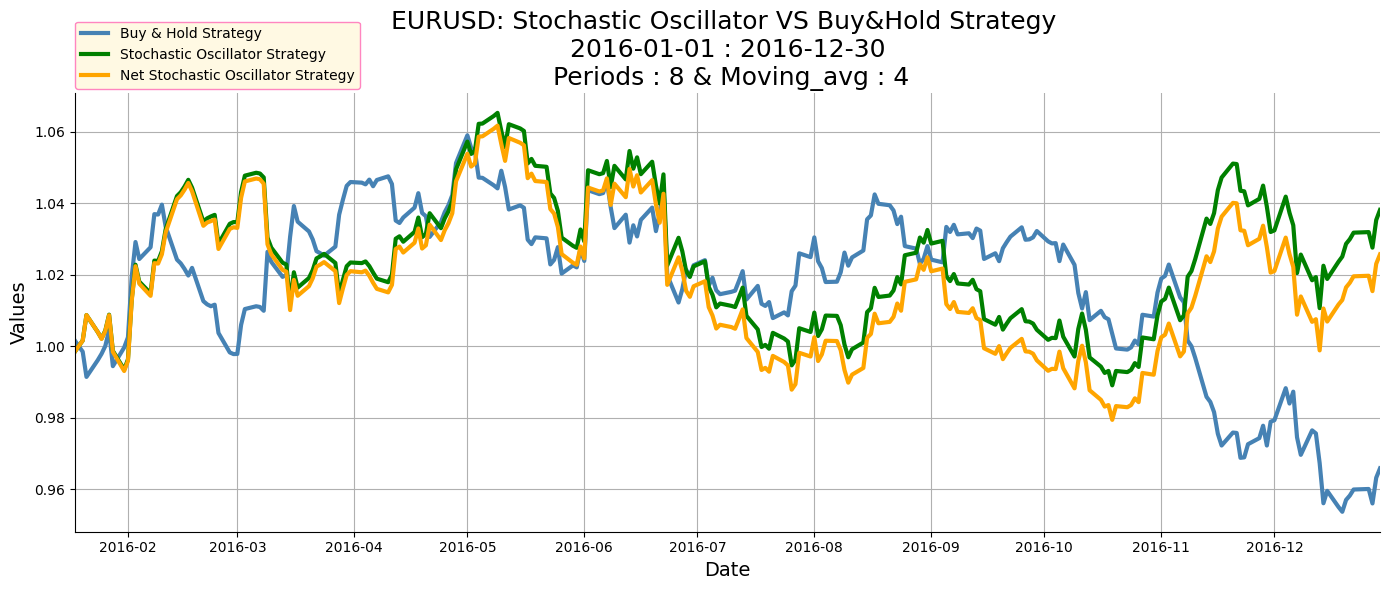

In [89]:
so.plot_results()

In [90]:
so.get_data()

,Open,High,Low,Close,roll_low,roll_high,K,D
2016-01-17,1.09233,1.09280,1.08692,1.08920,1.07713,1.09846,56.586967,63.729662
2016-01-18,1.08928,1.09392,1.08595,1.09078,1.08032,1.09846,57.662624,62.089034
2016-01-19,1.09060,1.09760,1.08774,1.08910,1.08050,1.09846,47.884187,59.102487
2016-01-20,1.08896,1.09218,1.07778,1.08751,1.07778,1.09846,47.050290,52.296017
2016-01-21,1.08742,1.08766,1.07892,1.07983,1.07778,1.09846,9.912959,40.627515
...,...,...,...,...,...,...,...,...
2016-12-22,1.04355,1.04694,1.04267,1.04554,1.03524,1.06700,32.430730,23.150189
2016-12-26,1.04540,1.04634,1.04324,1.04570,1.03524,1.05398,55.816435,34.333517
2016-12-27,1.04561,1.04798,1.03723,1.04130,1.03524,1.04994,41.224490,39.027234
2016-12-28,1.04136,1.04941,1.04085,1.04914,1.03524,1.04994,94.557823,56.007370


In [91]:
so.optimized_trading_strategy(periods_range=(1,20,1) , moving_avg_range=(1,7,1))

Starting optimization ... This may take time depending on the range size.
Optimal Parameters found : periods 18 | best Moving_avg : 5


Performance,Stochastic Oscillator: symbol : EURUSD | periods : 18 | moving_avg : 5
Strategy,116.55%
Buy & Hold,96.35%
Out Performance,20.21%
Ann. Return Buy & Hold,-3.96%
Ann. Return Strategy,16.29%
Ann. Risk Buy & Hold,8.20%
Ann. Risk Strategy,8.18%


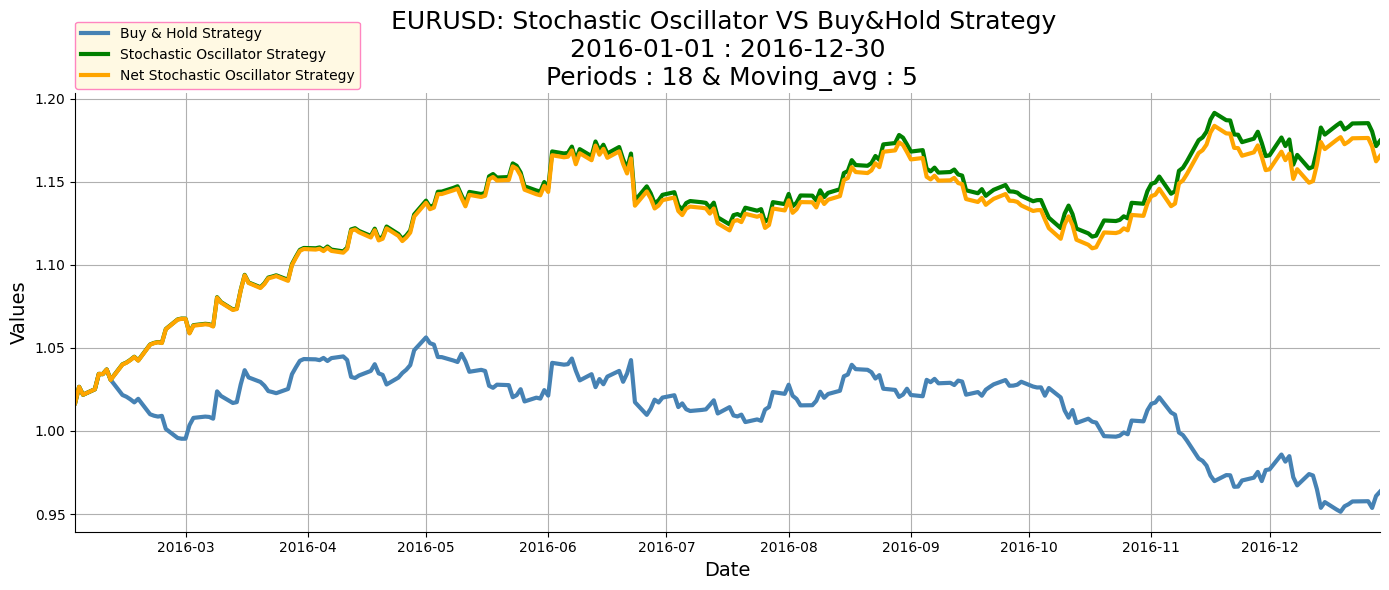

In [92]:
so.plot_results()